# Анализ А/В-теста новой фичи

## Цель теста: проверить, влияет ли новая фича на конверсию.
## Данные взяты из Kaggle. Ожидаемый результат - рост конверсии.

In [21]:
# 1. Загрузка и первичная разведка данных (Data Profiling)

import pandas as pd

df = pd.read_csv('ab_test_dataset.csv')

print(df.head())
print()
df.info()
print()
print(df.isna().sum())

   user_id    variant country       os  is_converted      assignment_date  \
0   228752  treatment   Italy  Android             0  2026-06-14 12:13:00   
1   120528    control   Spain  Android             0  2026-07-07 18:46:00   
2   103538  treatment   Italy  Android             0  2026-07-03 04:16:00   
3   213462  treatment   Italy      iOS             0  2026-06-10 21:08:00   
4   130506  treatment      UK      iOS             1  2026-06-05 23:13:00   

                 conversion_date  prior_30d_sessions  is_existing_user  
0                            NaN                 2.0               1.0  
1                            NaN                 2.0               1.0  
2                            NaN                 3.0               1.0  
3                            NaN                 3.0               1.0  
4  2026-06-06 13:22:56.108119806                 4.0               1.0  

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 9 columns):

### Вывод: пропуски в conversion_date, prior_30d_sessions и is_existing_user логически обоснованы. Данные чистые, можно приступать к проверке.

In [10]:
# Sanity Check: проверка баланса групп и наличия дубликатов

print("=== Размеры групп ===")
print(df['variant'].value_counts())

print("\n=== Дубликаты user_id ===")
print(df.duplicated(subset=['user_id']).sum())

print("\n=== Конверсия по группам ===")
print(df.groupby('variant')['is_converted'].mean() * 100)

=== Размеры групп ===
variant
treatment    75000
control      75000
Name: count, dtype: int64

=== Дубликаты user_id ===
0

=== Конверсия по группам ===
variant
control       9.213333
treatment    10.608000
Name: is_converted, dtype: float64


### Вывод: группы сбалансированы, дубликатов нет, тест валиден.

In [3]:
# Статистический тест (Z-тест для пропорций)
# Использую Z-тест для пропорций, так как конверсия - бинарный признак, а выборка достаточно велика

from statsmodels.stats.proportion import proportions_ztest

conversions = df.groupby('variant')['is_converted'].sum()
nobs = df.groupby('variant')['user_id'].count()
stat, p_value = proportions_ztest(conversions, nobs)

print(f"Z-статистика: {stat:.4f}")
print(f"p-value: {p_value}")

Z-статистика: -9.0385
p-value: 1.5878881974766166e-19


### Вывод: p-value < 0.05, Z-статистика отрицательная. Фича значимо повышает конверсию.

In [4]:
# Сегментный анализ: проверка влияния ОС на конверсию

print("=== Конверсия по ОС и группам ===")
print(df.groupby(['os', 'variant'])['is_converted'].mean() * 100)

=== Конверсия по ОС и группам ===
os       variant  
Android  control       8.916245
         treatment    10.304906
iOS      control       9.858583
         treatment    11.353925
other    control       8.338638
         treatment     8.430769
Name: is_converted, dtype: float64


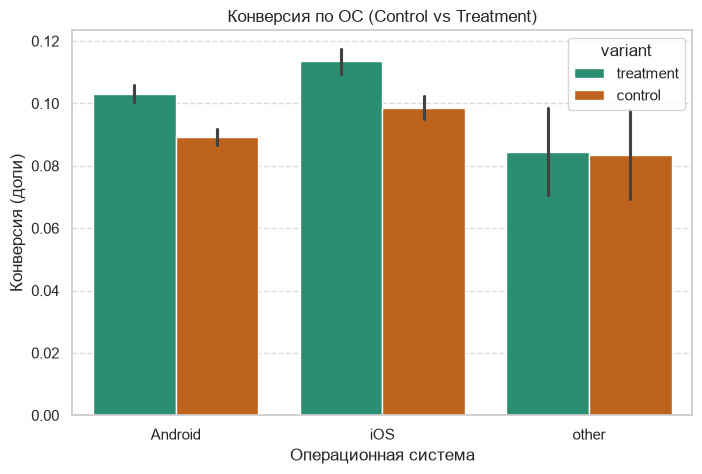

In [39]:
# Визуализация результатов

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style = 'whitegrid', palette = 'muted')

plt.figure(figsize=(8, 5))
sns.barplot(data = df, x = 'os', y = 'is_converted', hue = 'variant', palette = 'Dark2')
plt.title('Конверсия по ОС (Control vs Treatment)')
plt.ylabel('Конверсия (доли)')
plt.xlabel('Операционная система')
plt.grid(axis = 'y', linestyle = '--', alpha = 0.7)
plt.savefig('conversion_by_os.png', dpi = 300, bbox_inches = 'tight')
plt.show()

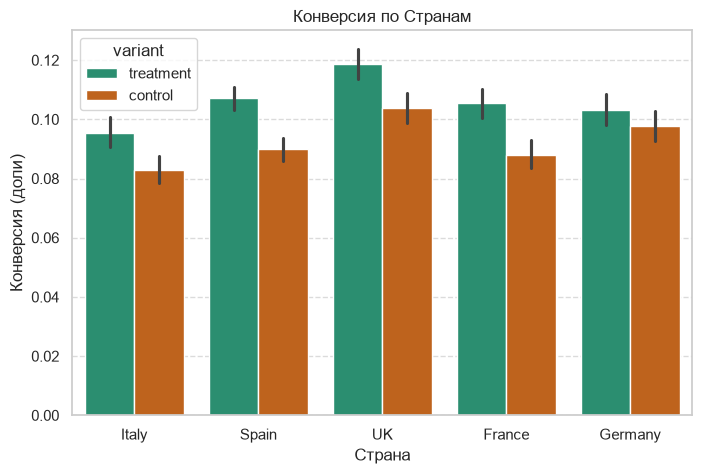

In [34]:
plt.figure(figsize=(8, 5))
sns.barplot(data = df, x = 'country', y = 'is_converted', hue = 'variant', palette = 'Dark2')
plt.title('Конверсия по Странам')
plt.ylabel('Конверсия (доли)')
plt.xlabel('Страна')
plt.grid(axis = 'y', linestyle = '--', alpha = 0.7)
plt.show()

### Вывод: прирост конверсии в Германии меньше, чем в других странах. Проверим, связано ли это с ОС, которой пользуется подавляющее число пользователей.

In [16]:
country_os_counts = pd.crosstab(df['country'], df['os'])
print(country_os_counts)

os       Android    iOS  other
country                       
France     18328   9656    537
Germany    16720   7924    742
Italy      19398   7203    519
Spain      28936  12254    815
UK         14241  12144    583


## Вывод: низкая конверсия в Германии не связана с ОС. Проверим, не было ли сбоев в работе продукта в Германии, а также, насколько активны были пользователи из Германии.

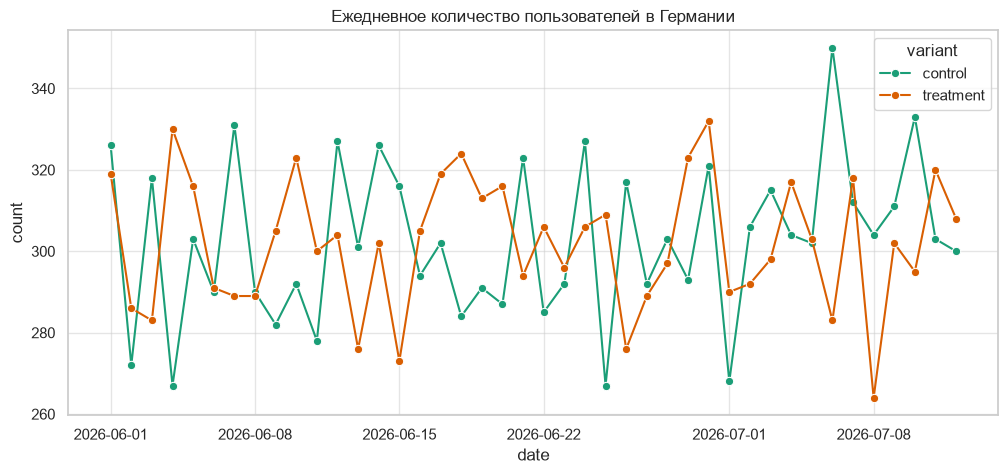

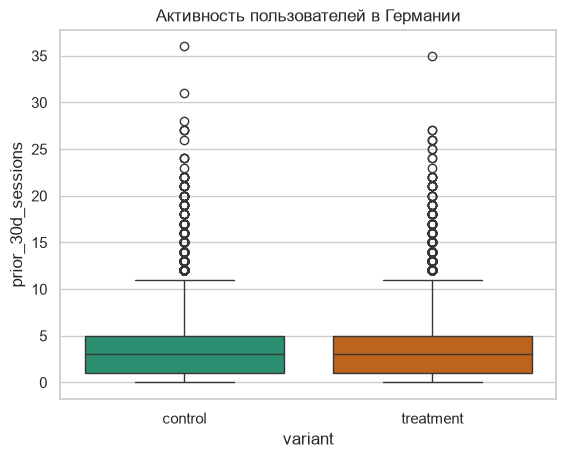

In [38]:
df_germany = df[df['country'] == 'Germany'].copy()
df_germany['date'] = pd.to_datetime(df_germany['assignment_date']).dt.date
germany_daily = df_germany.groupby(['date', 'variant'])['is_converted'].agg(['count', 'mean']).reset_index()
germany_daily_sorted = germany_daily.sort_values('date')

plt.figure(figsize=(12, 5))
sns.lineplot(data = germany_daily_sorted, x = 'date', y = 'count', hue = 'variant', palette = 'Dark2', marker = 'o')
plt.title('Ежедневное количество пользователей в Германии')
plt.grid(True, alpha = 0.5)
plt.show()

sns.boxplot(data=df_germany, x = 'variant', y = 'prior_30d_sessions', hue = 'variant', palette = 'Dark2')
plt.title('Активность пользователей в Германии')
plt.show()

## Вывод: график количества пользователей ровный, минимальное значение составляет 264 человека. Технических сбоев не было. Боксплот активности пользователей показал, что группы сбалансированы по активности

## Финальный вывод: фича работает на Android и iOS, на Other - нет. 
## Рекомендация: внедрять на Android и iOS.
## !!! Германия показала наименьший, по сравнению с другими странами, прирост конверсии. Для более глубокого анализа и поиска причины этого данных недостаточно.